This notebook shows how to use a python scripts to extract data points from a model with an arbitrary grid to points from the sea ice thickness CDR https://psc.apl.uw.edu/sea_ice_cdr/

In [ ]:
import logging
import os
import sys

sys.path.append("/home/axel/ax_python_lib/im")
sys.path.append("/home/axel/ax_python_lib/thickCDR/")
sys.path.append("/home/axel/ax_python_lib/axel_utilities")
import axutil
# various utilities for model data manipulation
import ax_im_utils as im

# looad routines from the match_thickCDR_model library
from match_thickCDR_model import *

%load_ext autoreload
%autoreload 2"

Edit the driver() function in match_thickCDR_model.py to follow below step

In [4]:
logging.basicConfig(stream=sys.stdout, level=logging.INFO)
# Specify the location of the thickness CDR netcdf file

## Specify the location of the thickness CDR data file 

In [ ]:
cdr_file = "/home/axel/projects/sea_ice_cdr/idl/axel_cdr/ncdf_dir/uThickCDR_summaries.20251010_V1.0.nc"

## Do some set ups for the specific model

In [32]:
gridName = "360X120"  # GridName, used to get anciallary data for the grid
model_group = ""
model_id = "2sstC"
dist_thresh = 25.0  # maximum between grid cell center and observation
nt = 46  # number of years in data set
file_varnames = ["hiday", "snowday"]  # when using daily variables
model_path = "/data/axel0/model_results/2sst/nc/"  # path to model data

Some additional configuration. These data would have to be supplied when a model that isn't configured in the utitlies is used

In [ ]:
g = im.gridInfo(gridName)
nx = g.nx # number of grid cells in the x dimeinson
ny = g.ny # number of grid cells in the y dimension

# specify the directory where the model input in located
model_path = "/data/axel0/model_results/" + model_group + "/" + model_id + "/nc/"

# this is where extracted data will be saved
output_root = "/home/axel/ax_python_lib/thickCDR/extractDir/"
#   this is the directory where the output is located
output_path = output_root + "/" + gridName + "/" + model_id + "/"
if not (os.path.isdir(output_path)):
    logging.info("Extraction Directory: %s doesn't exists will be made", output_path)
    os.makedirs(output_path, exist_ok=True)
#  Below is thickness extractions. Those are the variable names in the netcdf files that contain ice thickness and snowdepth
ncdf_varnames = ["sit", "sisnthick"]
#   open the CDR thickness file and get all the sources, if one wants to see the list)
cdr = xr.open_dataset(cdr_file)
sources = np.unique(cdr.SOURCE.values).tolist()
print(sources)
cdr.close()
# these sources don't have overlap so remove them.
sources.remove("AWI-WS")
sources.remove("USSUB-HI")
#sources = ["AIR-EM", "BGEP"]  # this would only extract data for BGEP and AIR-EM sources. If all sources are to be extracted just set the sources array as shown above

## Run the extraction looop for the above specfied sources

In [ ]:
# set to True unless you've done the extract before
match = True
merge = True
for source in sources:
    print(source)
    id = model_id + "_" + source  # name used for identifcation inside of file
    cdr_data, cdr_ds = read_thickCDR(source=source)
    logging.info("Done reading cdr_data for %s: ", source)
    # those are the output files
    match_pointDB_file = (
        output_path
        + model_id
        + ".matchDB."
        + source
        + "."
        + file_varnames[0]
        + "."
        + file_varnames[1]
        + ".nc"
    )
    merged_cdr_model_file = (
        output_path
        + model_id
        + ".merged."
        + source
        + "."
        + file_varnames[0]
        + "."
        + file_varnames[1]
        + ".nc"
    )
    model_ds = load_model_data(model_path, file_varnames, nx, ny, nt)
    if match:
        pmds = make_match_points_db(
            cdr_data=cdr_data,
            cdr_file=cdr_file,
            model_path=model_path,
            gridName=gridName,
            file_varnames=file_varnames,
            ncdf_varnames=ncdf_varnames,
            match_pointDB_file=match_pointDB_file,
            id=id,
            source=source,
            dist_thresh=dist_thresh,
            ds=model_ds,
        )
        if not isinstance(pmds, xr.Dataset):
            logging.info("skipping: %s ", source)
            continue
        pmds.close()
    if merge:
        obsAndModel = merge_pointDB_withCDR(
            cdr_ds=cdr_ds,
            cdr_file=cdr_file,
            match_pointDB_file=match_pointDB_file,
            merged_cdr_model_file=merged_cdr_model_file,
            ncdf_varnames=ncdf_varnames,
            source=source,
        )
        cdr_ds.close()

## Plot Scatter Plot and Histograms for observed and modeled ice thickness 

Reading data from  /home/axel/ax_python_lib/thickCDR/extractDir_2019v/
['CryoSat-AWI']
CryoSat-AWI
168245
INFO:root:Number of missing Draft values : 0
INFO:root:Number of missing THICK values : 0
INFO:root:Number of missing THICK_ICE_SNOW values : 0

Coordinates of Missing Values:
cdr_index: []
model_time: []
lon: []
lat: []
False
False
[0.47867831 0.69780218]
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.594
Model:                            OLS   Adj. R-squared:                  0.594
Method:                 Least Squares   F-statistic:                 2.460e+05
Date:                Wed, 26 Nov 2025   Prob (F-statistic):               0.00
Time:                        15:52:28   Log-Likelihood:            -1.0746e+05
No. Observations:              168245   AIC:                         2.149e+05
Df Residuals:                  168243   BIC:                         2.149e+05
Df Mo

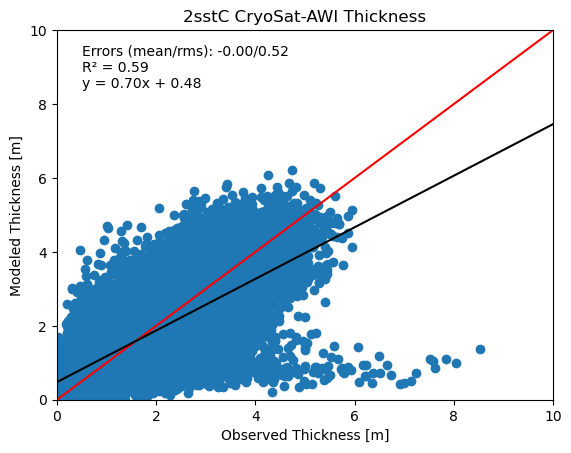

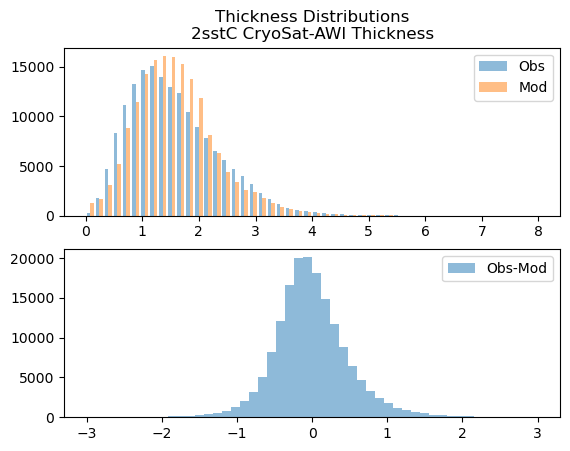

In [37]:
model_id='2sstC'
gridName='360X120'
#select_sources=['BGEP','IOS-EBS','IOS-CHK','AIR-EM']
#select_sources=['AIR-EM','BGEP']
#select_sources=['BGEP']
select_sources=['CryoSat-AWI']
input_root="/home/axel/ax_python_lib/thickCDR/extractDir_2019v/" # directory that containes extracted points merged with thickness CDR data
obsAndModel=readMerged(model_id,gridName, sources=select_sources,input_root=input_root)
obsAndModel.load() # get some kind of dask error if I don't load the data set

# compute draft/thickness/and thickness_ice_snow variables for all observations. 
# The thickness CDR contains draft, thickness and ice+snow measurements.
# model snow thickness is used to for the conversion. 

obsAndModel=toThick(obsAndModel)
title=model_id +" " +":".join(select_sources) +' Thickness'
#title="All CDR"
fig,ax,results=scatter_plot(obsAndModel,model_id, title=title,draft=False)
fig,ax0,ax1= plot_histograms(obsAndModel,model_id, title=title)

try draft

['BGEP']
BGEP
693
INFO:root:Number of missing Draft values : 8
INFO:root:Number of missing THICK values : 8
INFO:root:Number of missing THICK_ICE_SNOW values : 8

Coordinates of Missing Values:
cdr_index: [2520000 2520005 2520006 2520007 2520008 2520009 2520010 2520011]
model_time: ['2022-10-17T00:00:00.000000000' '2023-03-17T00:00:00.000000000'
 '2023-04-16T00:00:00.000000000' '2023-05-17T00:00:00.000000000'
 '2023-06-16T00:00:00.000000000' '2023-07-17T00:00:00.000000000'
 '2023-08-17T00:00:00.000000000' '2023-09-16T00:00:00.000000000']
lon: [209.65 209.65 209.65 209.65 209.65 209.65 209.65 209.65]
lat: [75.06 75.06 75.06 75.06 75.06 75.06 75.06 75.06]
False
False
[0.22600686 1.20207313]
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.736
Model:                            OLS   Adj. R-squared:                  0.735
Method:                 Least Squares   F-statistic:             

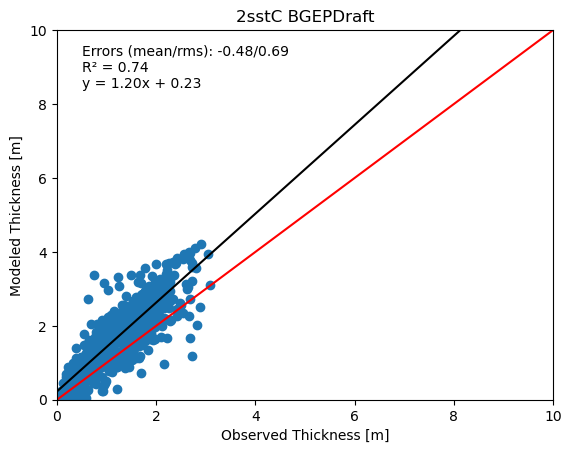

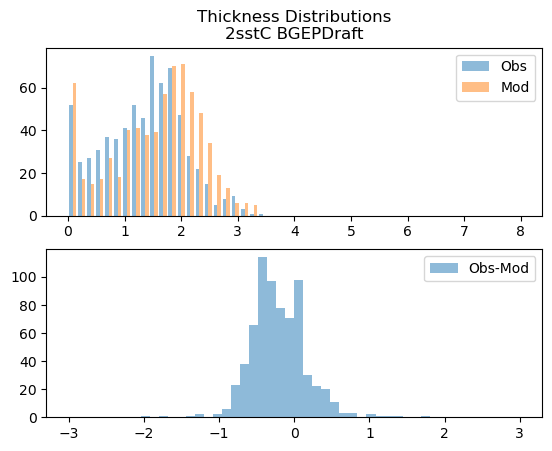

In [24]:
model_id='2sstC'
gridName='360X120'
#select_sources=['BGEP','IOS-EBS','IOS-CHK','AIR-EM']
select_sources=['AIR-EM','BGEP']
select_sources=['BGEP']
input_root="/home/axel/ax_python_lib/thickCDR/extractDir/" # directory that containes extracted points merged with thickness CDR data
obsAndModel=readMerged(model_id,gridName, sources=select_sources,input_root=input_root)
obsAndModel.load() # get some kind of dask error if I don't load the data set

# compute draft/thickness/and thickness_ice_snow variables for all observations. 
# The thickness CDR contains draft, thickness and ice+snow measurements.
# model snow thickness is used to for the conversion. 

obsAndModel=toThick(obsAndModel)
title=model_id +" " +":".join(select_sources) + "Draft"
#title="All CDR"
fig,ax,results=scatter_plot(obsAndModel,model_id, title=title,draft=True)
fig,ax0,ax1= plot_histograms(obsAndModel,model_id, title=title)

## Demonstrate how subsetting by space can be done

In [2]:
import geopandas as gpd
from cartopy.io.shapereader import Reader
from cartopy.feature import ShapelyFeature 
from shapely.geometry import Point,MultiPoint,Polygon, mapping
from model_maps_arctic import map_arctic_ortho,map_arctic_region,arctic_map_outline,ax_reset_norm

In [3]:
model_id='2sstC'
gridName='360X120'
#select_sources=['BGEP','IOS-EBS','IOS-CHK','AIR-EM']
#select_sources=['AIR-EM','BGEP']
select_sources=None
input_root="/home/axel/ax_python_lib/thickCDR/extractDir/" # directory that containes extracted points merged with thickness CDR data
obsAndModel=readMerged(model_id,gridName, sources=select_sources,input_root=input_root)
obsAndModel.load() # get some kind of dask error if I don't load the data set

# compute draft/thickness/and thickness_ice_snow variables for all observations. 
# The thickness CDR contains draft, thickness and ice+snow measurements.
# model snow thickness is used to for the conversion. 
obsAndModel=toThick(obsAndModel)
title="Subset By Space"

None
427833

Coordinates of Missing Values:
cdr_index: [ 2520000  2520005  2520006 ... 21025034 21025035 21025036]
model_time: ['2022-10-17T00:00:00.000000000' '2023-03-17T00:00:00.000000000'
 '2023-04-16T00:00:00.000000000' ... '2012-03-17T00:00:00.000000000'
 '2012-03-17T00:00:00.000000000' '2012-03-17T00:00:00.000000000']
lon: [209.65 209.65 209.65 ... 341.36 339.97 338.65]
lat: [75.06 75.06 75.06 ... 71.55 70.38 69.23]


In [11]:
cdr_file = "/home/axel/projects/sea_ice_cdr/idl/axel_cdr/ncdf_dir/uThickCDR_summaries.20251010_V1.0.nc"
cdr = xr.open_dataset(cdr_file)
sources = np.unique(cdr.SOURCE.values).tolist()
print(sources)

['AIR-EM', 'AWI-GS', 'AWI-WS', 'BGEP', 'BIO_LS', 'CanCoast', 'CryoSat-AWI', 'Davis_St', 'ENVISAT', 'ICESAT1-G', 'IOS-CHK', 'IOS-EBS', 'IceBridge-QL', 'IceBridge-V2', 'NPEO', 'UKSUB-AN', 'UKSUB-DG', 'USSUB-AN', 'USSUB-DG', 'USSUB-HI']


In [15]:
obsAndModel=obsAndModel.where((obsAndModel.SOURCE!='CryoSat-AWI') & (obsAndModel.SOURCE!='ENVISAT') & (obsAndModel.SOURCE!='ICESAT1-G') ,drop=True)

In [16]:
obsAndModel.dims

FrozenMappingWarningOnValuesAccess({'cdr_index': 8534, 'Mean Max Min Sigma': 4})

# reduce dimension to only extract the Mean values. This is necessary for creating the panda data frame.

In [17]:
sub=obsAndModel.isel({'Mean Max Min Sigma':0})
sub['lon']=axutil.lonTo180(sub.lon) # appears necessary otherwise doesn't work. 
df=sub.to_dataframe()
geometry = gpd.points_from_xy(df['lon'], df['lat'])
type(geometry)

geopandas.array.GeometryArray

## Create a geopanda data frame from the geometry data created above

In [18]:
gdf_points = gpd.GeoDataFrame(df,geometry=geometry, crs="EPSG:4326")

## Now define a Polygon in Lon,lat Space and create a geopanda polygon 

In [19]:
polygon = Polygon([(-100, 70), (-100, 82), (-180, 82), (-180, 70)])
gdf_polygon = gpd.GeoDataFrame(geometry=[polygon], crs="EPSG:4326")

## Check if the list of points (cdr observations) is inside the polygon defined above

In [20]:
points_within_polygon = gpd.sjoin(gdf_points, gdf_polygon, predicate='within')

## For checking that the subsetting works, plot the area that is selected

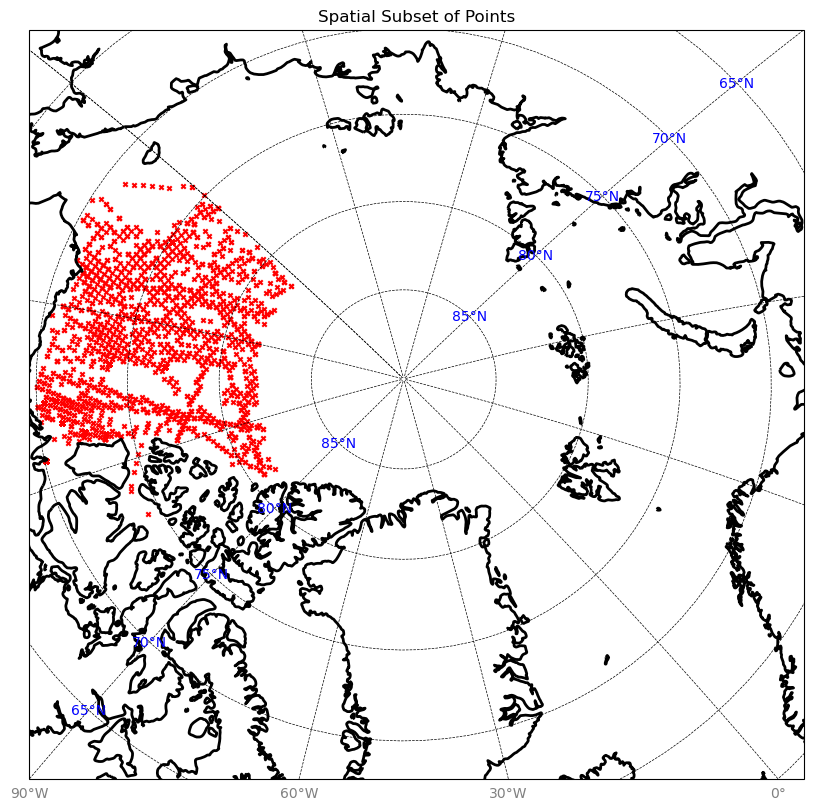

In [21]:
ax,fig,gl=arctic_map_outline("Spatial Subset of Points",land_fill=False)
plons=points_within_polygon['geometry'].x
plats=points_within_polygon['geometry'].y
ax.scatter(x=plons,y=plats,s=10,marker='x',color='red',transform=ccrs.PlateCarree())
plt.show()

## Now create the scatter plot and histogram of the subset

False
False
[0.77700109 0.62039643]
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.580
Model:                            OLS   Adj. R-squared:                  0.580
Method:                 Least Squares   F-statistic:                     4438.
Date:                Wed, 22 Oct 2025   Prob (F-statistic):               0.00
Time:                        15:06:08   Log-Likelihood:                -2458.6
No. Observations:                3212   AIC:                             4921.
Df Residuals:                    3210   BIC:                             4933.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0

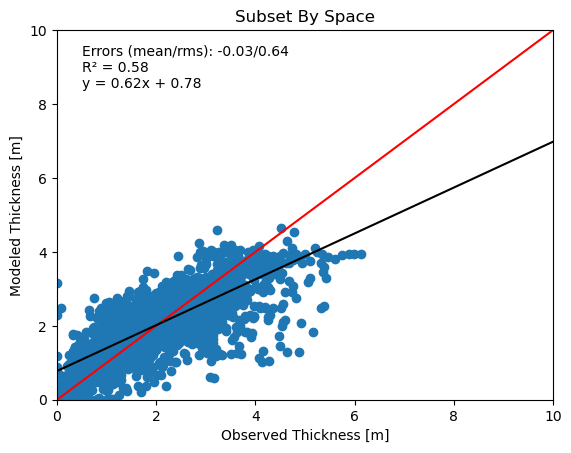

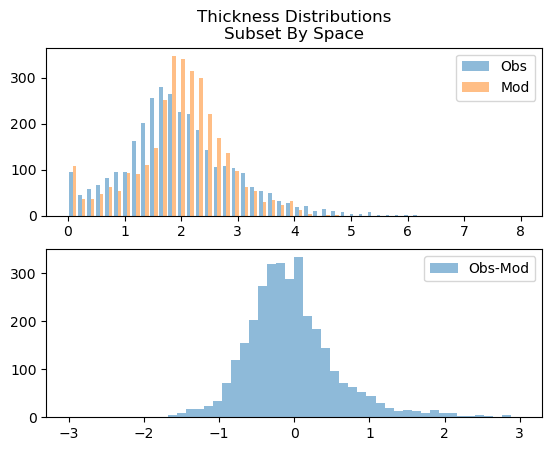

In [24]:
cdr_index=points_within_polygon.index
sub=obsAndModel.sel(cdr_index=cdr_index)
fig,ax,results=scatter_plot(sub,model_id, title=title)
fig,ax0,ax1= plot_histograms(sub,model_id, title=title)

False
False
[1.3010233  0.43888815]
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.425
Model:                            OLS   Adj. R-squared:                  0.425
Method:                 Least Squares   F-statistic:                     1488.
Date:                Wed, 22 Oct 2025   Prob (F-statistic):          3.15e-244
Time:                        15:13:38   Log-Likelihood:                -1271.0
No. Observations:                2015   AIC:                             2546.
Df Residuals:                    2013   BIC:                             2557.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1

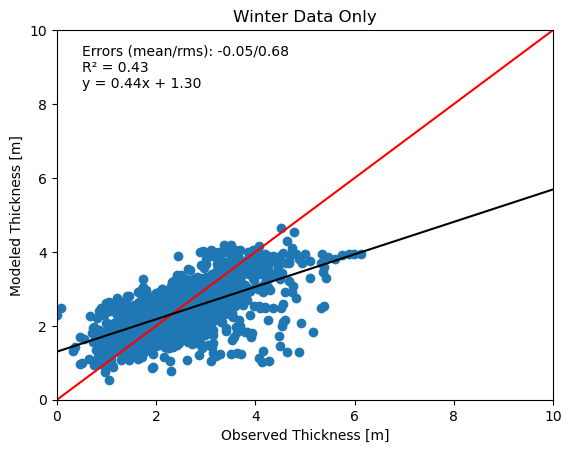

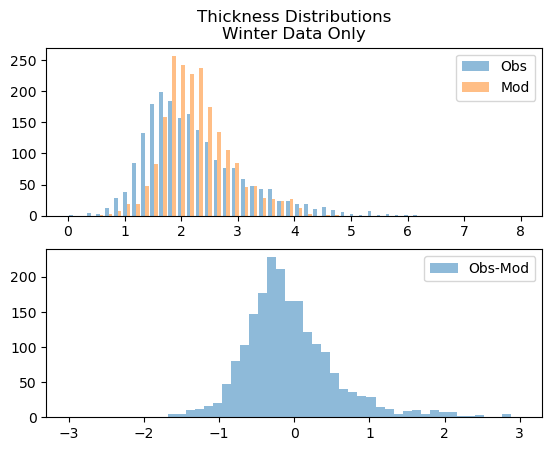

In [34]:
def is_winter(month):
    return (month >= 1) & (month <= 4)

cdr_index=points_within_polygon.index
sub=obsAndModel.sel(cdr_index=cdr_index)
sub=sub.isel(cdr_index=is_winter(sub['obs_time.month'])) # we have to select based on 
title='2sstC: Winter Data Only'
fig,ax,results=scatter_plot(sub,model_id, title=title)
fig,ax0,ax1= plot_histograms(sub,model_id, title=title)

False
False
[0.40475167 0.73086344]
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.656
Model:                            OLS   Adj. R-squared:                  0.656
Method:                 Least Squares   F-statistic:                     2087.
Date:                Wed, 22 Oct 2025   Prob (F-statistic):          1.24e-255
Time:                        15:14:34   Log-Likelihood:                -839.41
No. Observations:                1094   AIC:                             1683.
Df Residuals:                    1092   BIC:                             1693.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0

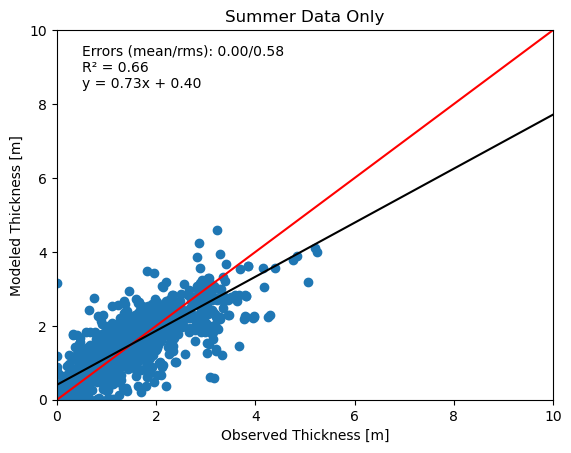

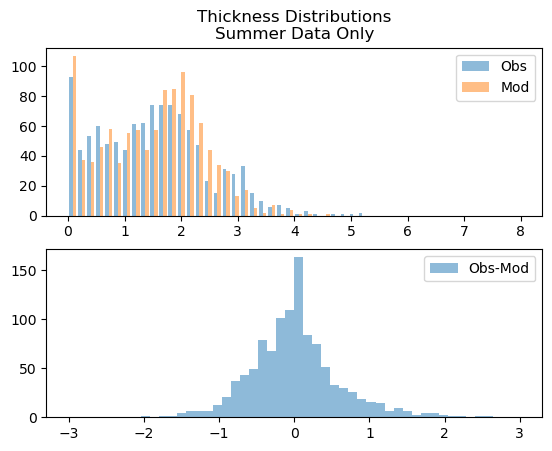

In [35]:
def is_summer(month):
    return (month >= 5) & (month <= 11)

cdr_index=points_within_polygon.index
sub=obsAndModel.sel(cdr_index=cdr_index)
sub=sub.isel(cdr_index=is_summer(sub['obs_time.month'])) # we have to select based on 
title='2sstC Summer Data Only'
fig,ax,results=scatter_plot(sub,model_id, title=title)
fig,ax0,ax1= plot_histograms(sub,model_id, title=title)

In [32]:
sub.obs_time

<xarray.DataArray 'obs_time' (cdr_index: 1138)> Size: 9kB
array(['2004-04-15T19:13:07.500000000', '2004-05-15T14:26:15.000000000',
       '2004-06-15T19:13:07.500000000', ...,
       '2019-04-09T00:00:00.000000000', '2019-04-09T02:26:15.000000000',
       '2019-04-09T02:26:15.000000000'],
      shape=(1138,), dtype='datetime64[ns]')
Coordinates:
  * cdr_index   (cdr_index) int64 9kB 2000008 2000009 ... 16170006 16170007
    model_time  (cdr_index) datetime64[ns] 9kB 2004-04-16 ... 2019-04-09
    lon         (cdr_index) float32 5kB 209.6 209.6 209.6 ... 249.8 248.3 247.3
    lat         (cdr_index) float32 5kB 75.06 75.06 75.06 ... 81.0 81.43 81.72

In [30]:
print((3+0.4)*928/1027)

3.072249269717624
